# Machine Learning Pipeline — Thrombolysis Decision Support

This notebook demonstrates a complete Machine Learning classification pipeline using synthetic data.

The objective is to illustrate:

- Data generation
- Preprocessing
- Model training
- Cross-validation
- Model evaluation
- Comparison of classification models

No real patient data is included.

In [3]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [4]:
X, y = make_classification(
    n_samples=500,
    n_features=15,
    n_informative=8,
    n_redundant=2,
    n_classes=2,
    random_state=42
)

feature_names = [
    f"feature_{i}"
    for i in range(X.shape[1])
]

X = pd.DataFrame(
    X,
    columns=feature_names
)

y = pd.Series(
    y,
    name="target"
)

print("Features:", X.shape)
print("Target:", y.shape)

Features: (500, 15)
Target: (500,)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (400, 15)
Test set: (100, 15)


In [6]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            X_train.columns
        )
    ]
)

In [7]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        random_state=42,
        eval_metric="logloss"
    )
}

In [8]:
results = []

for name, model in models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    pipeline.fit(
        X_train,
        y_train
    )

    y_pred = pipeline.predict(
        X_test
    )

    y_proba = pipeline.predict_proba(
        X_test
    )[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(
            y_test,
            y_pred
        ),
        "Precision": precision_score(
            y_test,
            y_pred
        ),
        "Recall": recall_score(
            y_test,
            y_pred
        ),
        "F1": f1_score(
            y_test,
            y_pred
        ),
        "AUC": roc_auc_score(
            y_test,
            y_proba
        )
    })

results_df = pd.DataFrame(
    results
)

results_df

,Model,Accuracy,Precision,Recall,F1,AUC
0,Logistic Regression,0.75,0.765957,0.72,0.742268,0.8104
1,Random Forest,0.86,0.860000,0.86,0.860000,0.9222
2,XGBoost,0.85,0.857143,0.84,0.848485,0.8944


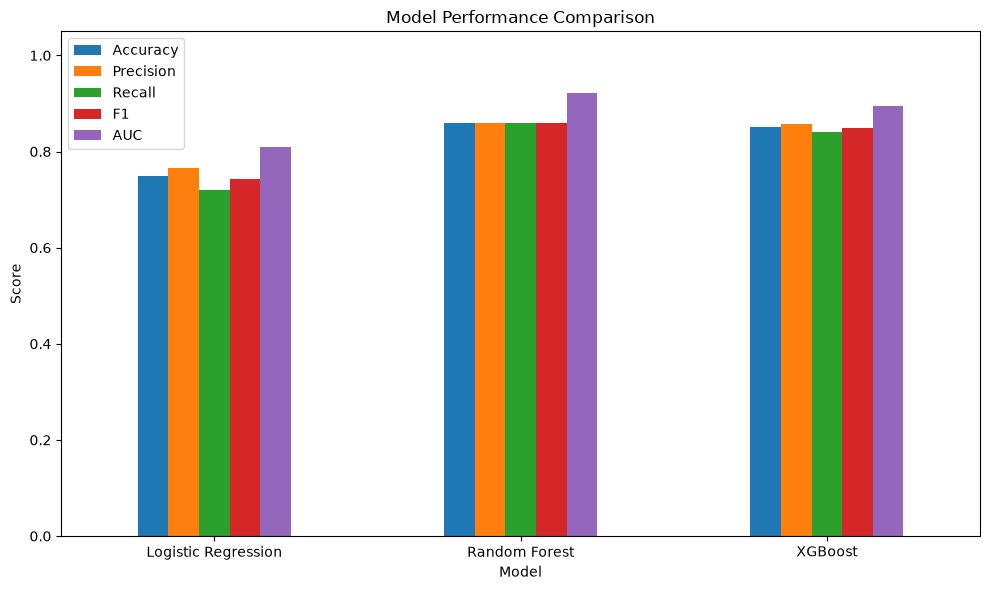

In [9]:
results_df.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "Model Performance Comparison"
)

plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

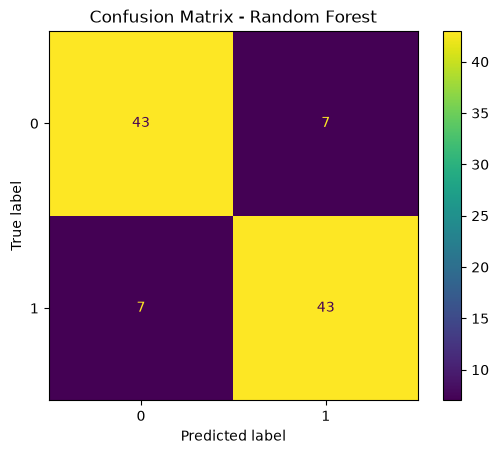

In [10]:
best_model_name = results_df.loc[
    results_df["AUC"].idxmax(),
    "Model"
]

best_model = models[
    best_model_name
]

best_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", best_model)
    ]
)

best_pipeline.fit(
    X_train,
    y_train
)

y_pred = best_pipeline.predict(
    X_test
)

cm = confusion_matrix(
    y_test,
    y_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot()

plt.title(
    f"Confusion Matrix - {best_model_name}"
)

plt.show()